In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings



In [2]:
warnings.filterwarnings("ignore")

In [3]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"]=(10,6)


In [4]:
df=pd.read_csv("consumer_shopping_behavior_survey.csv")


In [5]:
df.head()

,Response_ID,Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,...,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore,Best_Shopping_Mode
0,1,01/08/2026 12:30:25,20,Male,NaN,Philippines,"Under $1,000",Equal mix,Often,Physical stores,...,Never,Under $50,Digital wallet,"Yes, occasionally",6.0,7.0,2.0,More variety,No delivery wait,Online
1,2,21/06/2026 13:52:02,24,Male,Employed part-time,Brazil,"Under $1,000",In-store only,Often,Local e-commerce,...,Often,Under $50,Digital wallet,"No, never",5.0,8.0,3.0,NaN,Try product before buying,Offline
2,3,15/08/2026 04:24:18,22,Female,Student,India,"Under $1,000",Equal mix,Always,Local e-commerce,...,Sometimes,$150-300,Credit Card,"No, never",7.0,6.0,2.0,Better prices,Trust,Online
3,4,23/06/2026 21:24:21,20,Male,Student,NaN,"Under $1,000",In-store only,Occasionally,Brand websites,...,Never,Under $50,Debit Card,"No, never",8.0,7.0,3.0,Better prices,Try product before buying,Equal / both
4,5,20/08/2026 16:24:47,41,Male,Employed full-time,United States,"$1,000-3,000",Equal mix,Occasionally,NaN,...,Sometimes,$50-150,Debit Card,"No, never",6.0,8.0,2.0,Convenience,Trust,Equal / both


In [6]:
df.columns

Index(['Response_ID', 'Timestamp', 'Age', 'Gender', 'Occupation_Status',
       'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where',
       'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device',
       'Top_Spending_Category', 'Review_Influence_Score',
       'Social_Ads_Influence_Score', 'Price_Comparison_Frequency',
       'Discount_Importance_Score', 'Follows_Brands_On_Social',
       'Likely_To_Buy_After_Ad_Score', 'Makes_Shopping_List',
       'Impulse_Purchase_Frequency', 'Return_Frequency',
       'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method',
       'Uses_BNPL_Installments', 'Online_Shopping_Satisfaction_Score',
       'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency',
       'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode'],
      dtype='object')

In [7]:
df.shape

(500, 30)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 30 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Response_ID                         500 non-null    int64  
 1   Timestamp                           500 non-null    object 
 2   Age                                 478 non-null    object 
 3   Gender                              484 non-null    object 
 4   Occupation_Status                   479 non-null    object 
 5   Country_Region                      480 non-null    object 
 6   Monthly_Income_Range                479 non-null    object 
 7   Shop_Most_Where                     484 non-null    object 
 8   Online_Shopping_Frequency           481 non-null    object 
 9   Preferred_Platform                  486 non-null    object 
 10  Primary_Device                      492 non-null    object 
 11  Top_Spending_Category               476 non-n

In [9]:
df.isnull().sum()

Response_ID                            0
Timestamp                              0
Age                                   22
Gender                                16
Occupation_Status                     21
Country_Region                        20
Monthly_Income_Range                  21
Shop_Most_Where                       16
Online_Shopping_Frequency             19
Preferred_Platform                    14
Primary_Device                         8
Top_Spending_Category                 24
Review_Influence_Score                15
Social_Ads_Influence_Score            21
Price_Comparison_Frequency            26
Discount_Importance_Score             23
Follows_Brands_On_Social              11
Likely_To_Buy_After_Ad_Score          25
Makes_Shopping_List                   24
Impulse_Purchase_Frequency            16
Return_Frequency                      17
Avg_Monthly_Spend_NonEssentials       20
Preferred_Payment_Method              15
Uses_BNPL_Installments                12
Online_Shopping_

In [10]:
df.duplicated().sum()

0

In [11]:
df['Age']=pd.to_numeric(df['Age'],errors="coerce")
df['Timestamp']=pd.to_datetime(df['Timestamp'],format="%d/%m/%Y %H:%M:%S",errors="coerce")

In [12]:
df[['Age','Timestamp']].dtypes

Age                 float64
Timestamp    datetime64[ns]
dtype: object

In [13]:
df['Age'].describe()

count    470.000000
mean      25.019149
std        7.515276
min       16.000000
25%       20.000000
50%       22.000000
75%       30.000000
max       50.000000
Name: Age, dtype: float64

In [14]:
df['Reason_Prefer_Online'].value_counts()

Reason_Prefer_Online
More variety      170
Convenience       157
Better prices      81
Not applicable     38
Name: count, dtype: int64

In [56]:
bins = [0, 18, 26, 36, 51, float("inf")]
labels = ["Under 18", "18-25", "26-35", "36-50", "51+"]

df["Age_Group"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels,
    right=False
)

In [16]:
df['Age_Group'].value_counts()

Age_Group
18-25       228
26-35       110
under 15     78
36-50        54
50+           0
Name: count, dtype: int64

In [17]:
cols_to_fill=['Gender','Occupation_Status','Country_Region','Shop_Most_Where','Preferred_Platform','Preferred_Payment_Method']

In [18]:
for col in cols_to_fill:
    df[col]=df[col].fillna("Unknown")
    

In [19]:
df[cols_to_fill].isnull().sum()

Gender                      0
Occupation_Status           0
Country_Region              0
Shop_Most_Where             0
Preferred_Platform          0
Preferred_Payment_Method    0
dtype: int64

In [20]:
last6=['Online_Shopping_Satisfaction_Score',
       'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency',
       'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode']

In [21]:
dropoff=df[last6].isna().all(axis=1)

In [22]:
dropoff.sum()

30

In [58]:
df.loc[dropoff,'Timestamp'].dt.date.value_counts()

Timestamp
2026-07-07    2
2026-07-24    2
2026-07-27    2
2026-08-15    2
2026-08-21    1
2026-06-29    1
2026-07-16    1
2026-08-03    1
2026-07-10    1
2026-08-18    1
2026-08-02    1
2026-06-20    1
2026-07-02    1
2026-06-30    1
2026-08-24    1
2026-07-09    1
2026-07-06    1
2026-07-03    1
2026-08-17    1
2026-06-24    1
2026-07-28    1
2026-07-30    1
2026-08-19    1
2026-06-22    1
2026-07-05    1
2026-08-16    1
Name: count, dtype: int64

In [24]:
pd.crosstab(df['Shop_Most_Where'],df['Reason_Prefer_InStore'],dropna=False)

Reason_Prefer_InStore,No delivery wait,Not applicable,Trust,Try product before buying,NaN
Shop_Most_Where,,,,,
Equal mix,54,42,49,74,29
In-store only,15,10,16,21,9
Online only,43,20,51,46,5
Unknown,7,0,3,4,2


In [25]:
age_summary=df.groupby('Age_Group',observed=True).agg(
avg_satisafaction=('Online_Shopping_Satisfaction_Score','mean'),
avg_trust=('Trust_In_Online_Reviews_Score','mean'),
avg_regret=('Regret_After_Purchase_Frequency','mean'),
respondents=('Response_ID','count')
).round(2)

In [26]:
age_summary

,avg_satisafaction,avg_trust,avg_regret,respondents
Age_Group,,,,
under 15,7.25,6.06,2.06,78
18-25,7.04,6.11,2.29,228
26-35,7.17,6.14,2.17,110
36-50,7.02,6.48,1.93,54


In [27]:
top_countries=df['Country_Region'].value_counts().head(8).index

In [28]:
top_countries

Index(['India', 'United States', 'Brazil', 'Mexico', 'Kenya', 'Indonesia',
       'Egypt', 'Philippines'],
      dtype='object', name='Country_Region')

In [34]:
country_summary=df[df['Country_Region'].isin(top_countries)].groupby('Country_Region').agg(
    avg_satisfaction=('Online_Shopping_Satisfaction_Score','mean'),
    bnpl_regular_rate=('Uses_BNPL_Installments',lambda x:(x =='Yes,regularly').mean()),
    respondents=('Response_ID','count')
)
country_summary

,avg_satisfaction,bnpl_regular_rate,respondents
Country_Region,,,
Brazil,7.114286,0.0,38
Egypt,6.521739,0.0,25
India,6.779661,0.0,66
Indonesia,7.434783,0.0,26
Kenya,7.240000,0.0,26
Mexico,7.250000,0.0,35
Philippines,7.090909,0.0,23
United States,7.387755,0.0,56


In [37]:
occupation_summary=df.groupby('Occupation_Status').agg(
avg_impulse=('Impulse_Purchase_Frequency','mean'),
avg_discount_importance=('Discount_Importance_Score','mean'),
bnpl_regular_rate=('Uses_BNPL_Installments',lambda x:(x =='Yes,regularly').mean()),
respondents=('Response_ID','count')
).round(2).sort_values("avg_impulse",ascending=False)
occupation_summary

,avg_impulse,avg_discount_importance,bnpl_regular_rate,respondents
Occupation_Status,,,,
Employed part-time,2.86,3.94,0.0,71
Student,2.61,3.80,0.0,238
Unknown,2.50,3.67,0.0,21
Employed full-time,2.46,3.90,0.0,118
Self-employed,2.45,3.78,0.0,33
Unemployed,2.44,3.47,0.0,19


In [38]:
pivot_payment=pd.pivot_table(

    df,index='Shop_Most_Where',columns='Preferred_Payment_Method',
                                          
    values='Response_ID',aggfunc="count",fill_value=0
    
)

In [40]:
pivot_payment_pct=pivot_payment.div(pivot_payment.sum(axis=1),axis=0).round(2)
pivot_payment_pct

Preferred_Payment_Method,Cash,Credit Card,Debit Card,Digital wallet,Unknown
Shop_Most_Where,,,,,
Equal mix,0.14,0.21,0.27,0.35,0.02
In-store only,0.14,0.25,0.23,0.34,0.04
Online only,0.11,0.22,0.24,0.39,0.03
Unknown,0.12,0.12,0.31,0.38,0.06


In [ ]:
pivot_gender_spend=pd.pivot_table(
    df,index='Gender',columns='Top_Spending_Category',
    values='Response_ID',aggfunc="count",fill_value=0
)


Top_Spending_Category,Beauty & personal care,Books,Clothing,Electronics,Groceries,miscellaneous
Gender,,,,,,
Female,11,15,64,23,36,21
Male,20,16,98,39,44,25
Prefer not to say,5,5,11,12,9,7
Unknown,0,2,6,2,3,2


In [59]:
pivot_gender_spend_pct=pivot_gender_spend.div(pivot_gender_spend.sum(axis=1),axis=0).round(2)
pivot_gender_spend_pct

Top_Spending_Category,Beauty & personal care,Books,Clothing,Electronics,Groceries,miscellaneous
Gender,,,,,,
Female,0.06,0.09,0.38,0.14,0.21,0.12
Male,0.08,0.07,0.40,0.16,0.18,0.10
Prefer not to say,0.10,0.10,0.22,0.24,0.18,0.14
Unknown,0.00,0.13,0.40,0.13,0.20,0.13


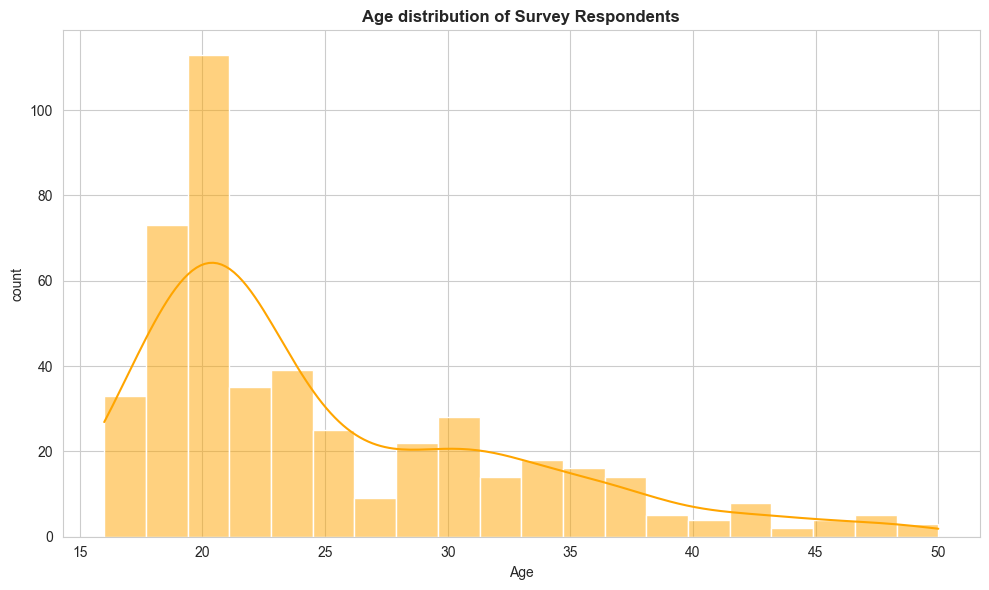

In [50]:
sns.histplot(df['Age'].dropna(),bins=20,kde=True,color='orange')
plt.title("Age distribution of Survey Respondents",fontweight='bold')
plt.xlabel('Age')
plt.ylabel('count')
plt.tight_layout()
plt.show()

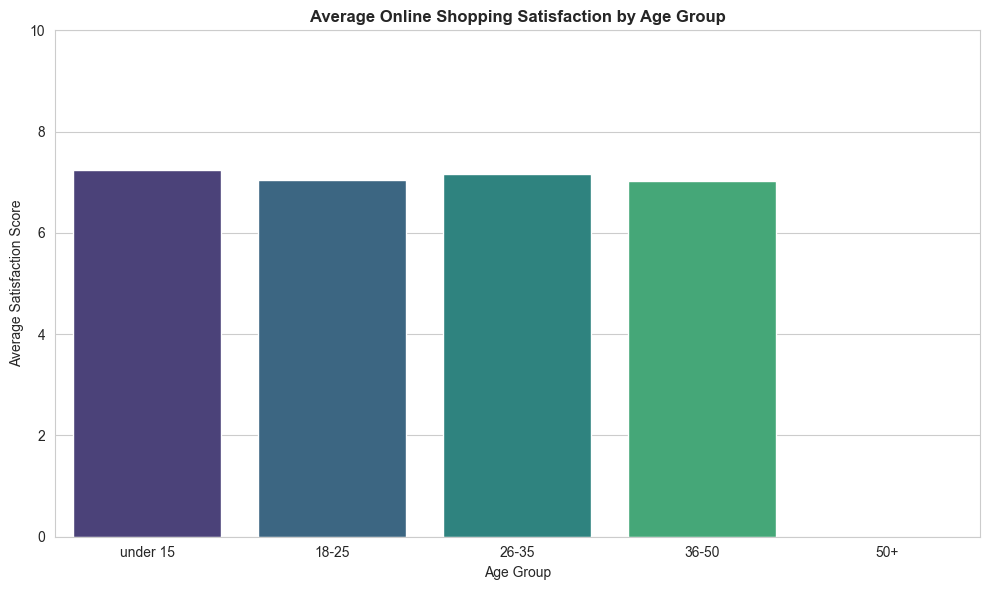

In [52]:
sns.barplot(x = age_summary.index,y = age_summary['avg_satisafaction'], palette="viridis")
plt.title("Average Online Shopping Satisfaction by Age Group",fontweight="bold")
plt.xlabel('Age Group')
plt.ylabel("Average Satisfaction Score")
plt.ylim(0,10)
plt.tight_layout()
plt.show()


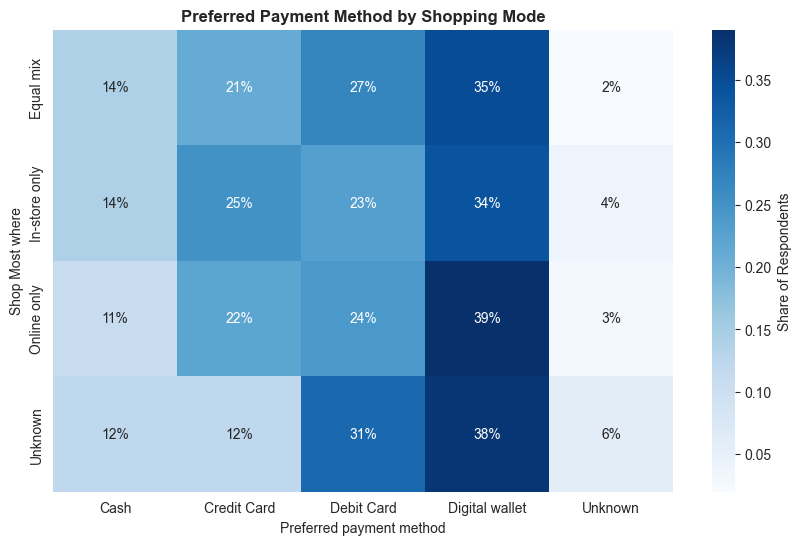

In [53]:
sns.heatmap(pivot_payment_pct,annot=True,cmap="Blues",fmt=".0%",cbar_kws={"label":"Share of Respondents"})
plt.title("Preferred Payment Method by Shopping Mode",fontweight="bold")
plt.xlabel("Preferred payment method")
plt.ylabel("Shop Most where")
plt.show()

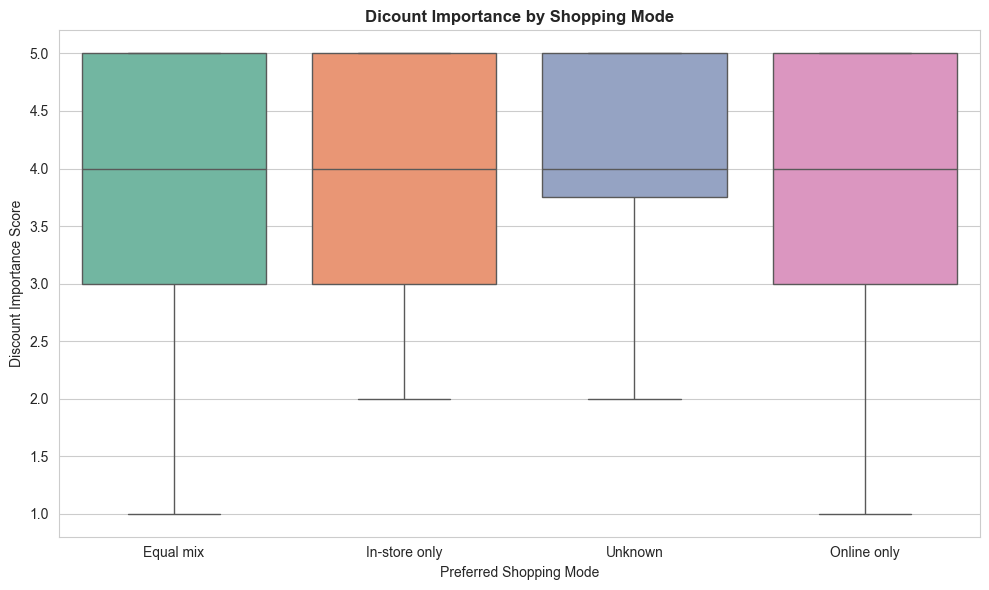

In [61]:
sns.boxplot(x='Shop_Most_Where',y='Discount_Importance_Score',data=df,palette="Set2")
plt.title("Dicount Importance by Shopping Mode",fontweight='bold')
plt.xlabel("Preferred Shopping Mode")
plt.ylabel("Discount Importance Score")
plt.tight_layout()
plt.show()